In [1]:
import numpy as np
import fastplotlib as fpl
import tifffile

from scipy.sparse.linalg import svds

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
Unable to find extension: VK_EXT_swapchain_colorspace
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD RADV POLARIS10 (ACO),DiscreteGPU,Vulkan,Mesa 20.3.5 (ACO)
❗ limited,"llvmpipe (LLVM 11.0.1, 256 bits)",CPU,Vulkan,Mesa 20.3.5 (LLVM 11.0.1)
✅,NVIDIA GeForce RTX 3080,DiscreteGPU,Vulkan,530.30.02
❌,"Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1)",Unknown,OpenGL,4.6 (Core Profile) Mesa 20.3.5


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [2]:
from matplotlib import pyplot as plt

In [3]:
%matplotlib inline

In [4]:
sub = tifffile.imread("./dendrites_rect_filtered.tif")

RFBOutputContext()

WGPU: request_device() is deprecated, use request_device_sync() instead.
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
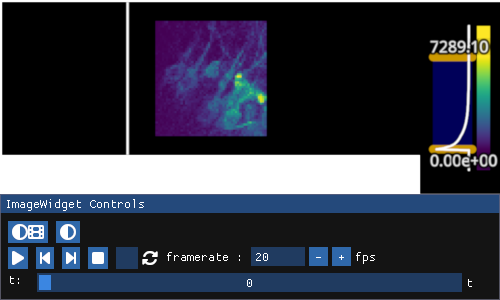

In [5]:
iw_sub = fpl.ImageWidget(sub, cmap="viridis")
iw_sub.show()

In [6]:
period_1 = (4255, 4420)
period_2 = (9250, 9800)
period_3 = (14150, 14490)

RFBOutputContext()

JupyterWgpuCanvas()
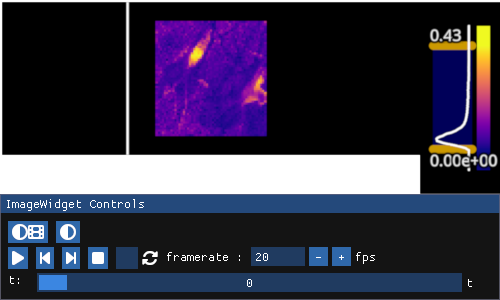

In [7]:
labels = np.load("./dendrites_15_spatial.npy").swapaxes(0, 1).T
fpl.ImageWidget(labels).show()

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/tools/_histogram_lut.py:217: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  hist, edges = np.histogram(data_ss, bins=self._nbins)


JupyterWgpuCanvas()
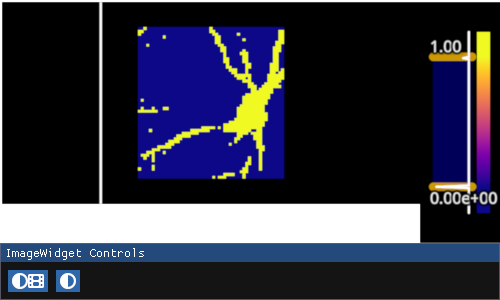

In [8]:
A = labels[10]
A[A < 0.08] = 0
A = A.astype(bool)

fpl.ImageWidget(A).show()

In [9]:
A_ixs = np.where(A)
A_shape = A.shape

In [10]:
def recover(pixels: np.ndarray, shape: tuple[int, int], indices: np.ndarray) -> np.ndarray:
    r = np.zeros(shape)
    r[indices] = pixels
    return r

In [11]:
Ya = sub[slice(*period_2), *A_ixs].T

In [12]:
Ya.shape

(437, 550)

In [13]:
from ipywidgets import IntSlider, VBox, HBox

In [37]:
iw_rec = fpl.ImageWidget(recover(Ya[:, 0], A.shape, A_ixs), cmap="viridis", figure_kwargs={"size": (520, 600)})
iw_rec.show()

g = iw_rec.managed_graphics[0]

g.vmin, g.vmax = Ya.min(), Ya.max()

fig_heatmap = fpl.Figure(size=(600, 600))
fig_heatmap[0, 0].add_image(Ya, cmap="viridis")

ts = IntSlider(min=0, max=Ya.shape[1] - 1, value=0)

def update_time(change):
    ix = change["new"]
    iw_rec.managed_graphics[0].data = recover(Ya[:, ix], A.shape, A_ixs)

ts.observe(update_time, "value")

HBox([VBox([iw_rec.show(), ts]), fig_heatmap.show()])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

In [15]:
Ya.nbytes / 1024 / 1024

0.9168624877929688

In [16]:
u, s, v = svds(Ya, k=10)

In [19]:
u = u[:, ::-1]
s = s[::-1]
v = v[::-1]

[]

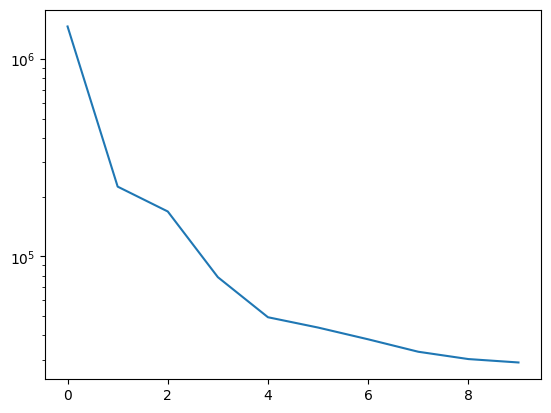

In [21]:
plt.plot(s)
plt.semilogy()

In [24]:
u.shape

(437, 10)

In [25]:
u_imgs = np.dstack([recover(u[:, i], A.shape, A_ixs).T for i in range(u.shape[1])]).T

RFBOutputContext()

JupyterWgpuCanvas()
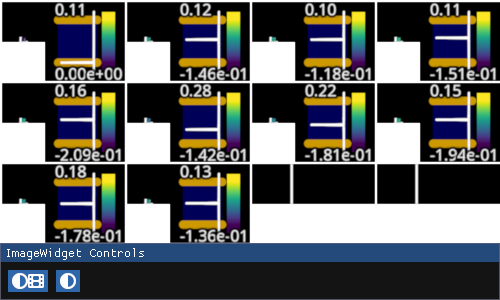

In [35]:
iw_u = fpl.ImageWidget([u_i for u_i in u_imgs], names=[str(i) for i in range(u.shape[1])],  cmap="viridis")
iw_u.show()

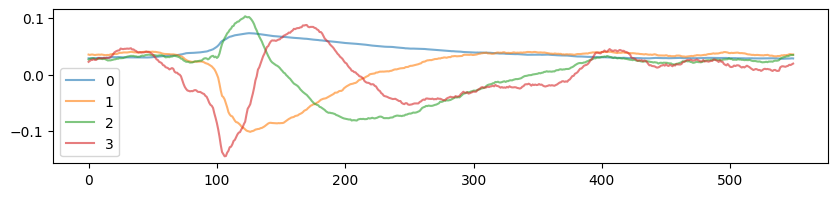

In [33]:
fig = plt.figure(figsize=(10, 2))

for i in range(4):
    plt.plot(v[i], label=i, alpha=0.6)

plt.legend()
plt.show()